# Results of the benchmark runs

The scores of every benchmark run under `results/gentrex-bench/`. The first
half compares the runs with each other, and the second half goes through
one run down to every value that isn't right.

| Part | Sections |
| --- | --- |
| The runs | Runs, software and models, the reports |
| Comparisons | Accuracy, held-out templates, dev and test, repeated runs, scanned copies, `gentrex select`, fields, commands, time |
| One run | Errors per report, variants, wrong reports, patient identification, kinds of report, fields, standard values, checks, every error |

[walkthrough.ipynb](walkthrough.ipynb) explains the four commands on one
report.

One job makes the runs that are compared here. It is
`evaluation/minerva/run_pipeline.lsf` on Minerva and
`evaluation/local/run_pipeline.sh` on your own machine
([`evaluation/`](../evaluation/README.md)). Open the notebook from the
Gentrex folder:

```bash
uv run --group notebook jupyter lab evaluation_results/analysis.ipynb
```

The scores are those of each run's `scores.json` and `scores.md`.
[Run the benchmark](../docs/development/run-benchmark.md) explains how the
scorer counts. Three kinds of numbers are computed here: the difference
between two runs, the intervals of groups and fields, and the accuracy of
`gentrex normalize` on values that were extracted right.

Some tables quote values from the reports. After a run on real reports,
clear the outputs before you save or share the notebook.

In [1]:
# The notebook group provides pandas and matplotlib.
# pyright: reportMissingImports=false

import collections
import pathlib

import benchruns as bench
import pandas as pd

runs = bench.load_runs()
print(f"{len(runs)} scored runs in results/gentrex-bench")

1 scored runs in results/gentrex-bench


## Runs

One row per scored run, named by its folder under `results/gentrex-bench/`.
`Setup` is the copy of the reports that the run read, with `no select` for
a run without `gentrex select`.

| Copy | What it is |
| --- | --- |
| `native` | The PDFs as printed, with a text layer. Nothing goes to OCR. |
| `scan` | Page images, as from an office scanner |
| `fax` | Page images, as from a fax |
| `mixed` | The native PDF with about a third of its pages scanned |
| `image` | Clean page images |

Numbers in brackets are 95% intervals.

In [2]:
pd.DataFrame(
    [
        {
            "Setup": bench.setup_of(run),
            "Split": run["split"],
            "Reports": run["reports"],
            "Report accuracy": bench.with_interval(run["main"]["report_accuracy"]),
            "Variant F1": bench.with_interval(run["main"]["variant_f1"]),
        }
        for run in runs.values()
    ],
    index=list(runs),
)

,Setup,Split,Reports,Report accuracy,Variant F1
20261117-201846,native,dev,99,88.9% (81.8% to 93.9%),96.0% (92.7% to 98.8%)


The comparisons take the newest run of each setup on one split, `SPLIT`.
Set it to `"dev"` while you tune, and to `"test"` for the numbers that you
report.

In [3]:
SPLIT = "dev"
chosen = {setup: runs[name] for setup, name in bench.newest(runs, SPLIT).items()}


def software(run):
    gentrex = run["runs"]["extract"]["gentrex"]
    changed = " with local changes" if gentrex.get("modified") else ""
    return {
        "Gentrex": f"{gentrex['version']}, commit {gentrex['commit'][:7]}{changed}",
        "Model server": ", ".join(
            sorted(set(filter(None, run["performance"]["server_versions"].values())))
        ),
        "GPUs": ", ".join(run["performance"]["gpu_names"]),
    }


pd.DataFrame(
    {
        setup: {"Run": name, **software(runs[name])}
        for setup, name in bench.newest(runs, SPLIT).items()
    }
).T

,Run,Gentrex,Model server,GPUs
native,20261117-201846,"0.1.0, commit 167e172",0.31.0,"NVIDIA H100 80GB HBM3, NVIDIA H100 80GB HBM3"


The models and reference data of these runs, as the first of them recorded
them in its `run.yaml`:

In [4]:
first = next(iter(chosen.values()))
settings = {command: run["settings"] for command, run in first["runs"].items()}
normalize = settings["normalize"]
pd.Series(
    {
        "Model of gentrex transcribe": settings["transcribe"]["ocr"]["model"],
        "Model of gentrex select": settings.get("select", {}).get("model"),
        "Model of gentrex extract": settings["extract"]["model"],
        "Models of gentrex normalize": ", ".join(
            model["name"] for model in (normalize.get("hpo") or {}).get("models", [])
        ),
        "HPO release": normalize.get("hpo_version"),
        "MONDO release": normalize.get("mondo_version"),
        "HGNC file": pathlib.Path(normalize.get("hgnc_path") or "").name,
        "ClinVar file": pathlib.Path(normalize.get("clinvar_path") or "").name,
        "Benchmark": first["benchmark"].get("version"),
        "Generator": first["benchmark"].get("generator"),
    },
    name="value",
    dtype=object,
).to_frame()

,value
Model of gentrex transcribe,lightonai/LightOnOCR-3-4B
Model of gentrex select,google/gemma-4-26B-A4B-it
Model of gentrex extract,google/gemma-4-31B-it
Models of gentrex normalize,"cambridgeltl/SapBERT-from-PubMedBERT-fulltext,..."
HPO release,2026-09-01
MONDO release,2026-11-03
HGNC file,hgnc_complete_set_2026-10-06.txt
ClinVar file,variant_summary_2026-11.txt.gz
Benchmark,v1
Generator,gentrex-synthetic-1


### The reports

Each report is printed with one template, has one kind of test and one
result, and carries challenge tags. A `held out` template is only in the
test split.

In [5]:
GROUPS = {
    "kind": "Kind of test",
    "scenario": "Result",
    "variants": "Variants in the report",
    "held_out": "Templates",
    "lab": "Template",
    "tag": "Challenge tag",
}


def composition(run, groups):
    """Returns the number of reports of each value of the named groups."""
    return pd.DataFrame(
        [
            {"Group": GROUPS[group], "Value": label, "Reports": numbers["reports"]}
            for group in groups
            for label, numbers in run["groups"].get(group, {}).items()
        ]
    ).set_index(["Group", "Value"])


print(
    f"{first['reports']} reports, {len(first['groups'].get('lab', {}))} templates,"
    f" {len(first['groups'].get('tag', {}))} challenge tags"
)
composition(first, ("kind", "scenario", "variants", "held_out"))

99 reports, 18 templates, 18 challenge tags


Reports
Group                  Value                     
Kind of test           array                   12
                       carrier                 16
                       exome                   16
                       karyotype                5
                       methylation              2
                       mito                     4
                       panel                   20
                       repeat                   5
                       single_gene              9
                       sma                      3
                       targeted                 7
Result                 carrier                 12
                       indeterminate            2
                       mixed                    5
                       negative                24
                       positive                41
                       secondary_finding        2
                       vus_only                13
Variants in the report 0                       30
                       1                       54
                       2 or more               15
Templates              seen in dev             99

Reports per template and per challenge tag. A report can carry several
tags.

In [6]:
composition(first, ("lab", "tag"))

Reports
Group         Value                                   
Template      carrier-banner                         5
              chart                                  7
              dx-banner                              6
              enterprise                             5
              exome-box                              5
              exome-findings                         5
              findings-grid                          6
              graybar-panel                          6
              karyotype                              5
              microarray-printout                    6
              one-page                               5
              patient-page                           5
              results-statement                      6
              screen-badge                           5
              snp-array                              5
              summary-line                           6
              summary-sidebar                        6
              teal-banner                            5
Challenge tag ambiguous_specimen                     8
              boilerplate_variant_notation           8
              explicitly_unavailable                 8
              family_history_distractor              8
              gene_list_distractor                   7
              late_page_evidence                     8
              legacy_gene_symbol                     8
              missing_optional_fields                8
              multiple_patient_ids                   4
              multiple_variants                      8
              negated_or_uncertain_phenotypes        8
              nonstandard_hgvs                       7
              provided_phenotype_page                8
              repeated_variant                       8
              similar_identifiers                    8
              table_split_across_pages               8
              trio_columns                           7
              unusual_date_format                    9

## Accuracy

- **Report accuracy** is the share of reports with nothing clinically
  wrong. The result category and the karyotype are right, every variant has
  the right gene, DNA change, copy number, classification and zygosity, and
  no variant is extra.
- **MRN and date of birth both right** is the share of reports that would
  be filed under the right patient.
- **Variant F1** combines variant recall, the share of true variants that
  Gentrex found, and variant precision, the share of Gentrex's variants
  that are true.

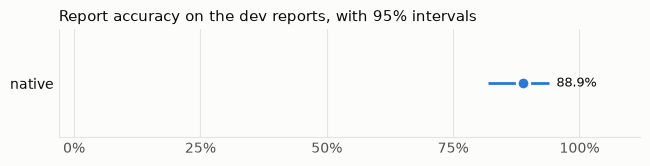

,Report accuracy,MRN and date of birth both right,Variant F1,Variant precision,Variant recall
native,88.9% (81.8% to 93.9%),77.8% (69.7% to 85.9%),96.0% (92.7% to 98.8%),92.3% (86.4% to 97.6%),100.0% (100.0% to 100.0%)


In [7]:
bench.intervals(
    {setup: run["main"]["report_accuracy"] for setup, run in chosen.items()},
    f"Report accuracy on the {SPLIT} reports, with 95% intervals",
)
MAIN = {
    "report_accuracy": "Report accuracy",
    "patient_match": "MRN and date of birth both right",
    "variant_f1": "Variant F1",
    "variant_precision": "Variant precision",
    "variant_recall": "Variant recall",
}
pd.DataFrame(
    {
        setup: {
            label: bench.with_interval(run["main"][name])
            for name, label in MAIN.items()
        }
        for setup, run in chosen.items()
    }
).T

### Held-out templates

Prompts and settings are tuned on the dev reports, and most templates are
in both splits. The test split also has templates of its own. The table
gives the report accuracy on those next to the accuracy on the templates
that dev has too. For a dev run it has one column.

In [8]:
def group_table(run, group):
    """Returns the report accuracy of each label of a group, with its interval."""
    return {
        label: bench.with_interval(
            bench.wilson(
                round(numbers["report_accuracy"] * numbers["reports"]),
                numbers["reports"],
            )
        )
        + f" of {numbers['reports']}"
        for label, numbers in run["groups"].get(group, {}).items()
    }


pd.DataFrame({setup: group_table(run, "held_out") for setup, run in chosen.items()}).T

,seen in dev
native,88.9% (81.2% to 93.7%) of 99


### Dev and test

The newest dev run and the newest test run of each setup. A test number
well below the dev number means the tuning didn't carry over.

In [9]:
by_split = {split: bench.newest(runs, split) for split in ("dev", "test")}
both = [setup for setup in by_split["dev"] if setup in by_split["test"]]
if not both:
    print("No setup has both a dev run and a test run yet.")
pd.DataFrame(
    {
        setup: {
            f"{title}, {split}": bench.with_interval(
                runs[by_split[split][setup]]["main"][name]
            )
            for name, title in (
                ("report_accuracy", "Report accuracy"),
                ("variant_f1", "Variant F1"),
            )
            for split in ("dev", "test")
        }
        for setup in both
    }
).T

No setup has both a dev run and a test run yet.


""


## Repeated runs

The same setup doesn't give the same answers twice. The model server
batches the requests differently in each run, and that changes a few
answers. For every setup with more than one run on `SPLIT`, the table gives
the lowest and highest report accuracy, and how many reports came out the
same in all runs.

A difference between two setups that is smaller than this spread means
little.

In [10]:
def spread(names):
    same = [runs[name] for name in names]
    accuracy = [run["main"]["report_accuracy"]["value"] for run in same]
    shared = set.intersection(*(set(run["by_report"]) for run in same))
    agree = sum(
        len({run["by_report"][report]["correct"] for run in same}) == 1
        for report in shared
    )
    return {
        "Runs": len(names),
        "Lowest report accuracy": bench.percent(min(accuracy)),
        "Highest report accuracy": bench.percent(max(accuracy)),
        "Reports with the same outcome in all runs": (
            f"{agree} of {len(shared)} ({bench.percent(agree / len(shared))})"
        ),
    }


repeated = {s: n for s, n in bench.repeats(runs, SPLIT).items() if len(n) > 1}
if not repeated:
    print(f"No setup has more than one {SPLIT} run yet.")
pd.DataFrame({setup: spread(names) for setup, names in repeated.items()}).T

No setup has more than one dev run yet.


""


## Scanned and faxed copies

All copies hold the same reports. `OCR requests` counts the pages that went
to the OCR model. `Values lost in transcribe` counts the true values whose
text was no longer in the transcribed pages.

`Difference to native` is the copy's report accuracy minus the native
copy's, on the reports that both runs scored. If its interval includes 0,
the two can't be told apart on these reports.

In [11]:
native = chosen.get("native")
pd.DataFrame(
    [
        {
            "Copy": setup,
            "OCR requests": run["performance"]["commands"]["transcribe"]["requests"],
            "Values lost in transcribe": sum(run["charges"]["transcribe"].values()),
            "Report accuracy": bench.percent(run["main"]["report_accuracy"]["value"]),
            "Difference to native": (
                bench.difference(native, run) if native and run is not native else ""
            ),
            "MRN and date of birth both right": bench.percent(
                run["main"]["patient_match"]["value"]
            ),
            "Variant F1": bench.percent(run["main"]["variant_f1"]["value"]),
        }
        for setup, run in chosen.items()
        if "select" in run["runs"]
    ]
).set_index("Copy")

,OCR requests,Values lost in transcribe,Report accuracy,Difference to native,MRN and date of birth both right,Variant F1
Copy,,,,,,
native,0,0,88.9%,,77.8%,96.0%


## With and without `gentrex select`

`gentrex select` drops pages before `gentrex extract` reads them, which
saves tokens and time. A page that is wrongly dropped takes its values with
it, and `Values lost in select` counts those.

`Pages kept` needs the run folder of `gentrex select` on this machine.

In [12]:
def select_numbers(run):
    commands = run["performance"]["commands"]
    decisions = bench.records(run, "select", "decisions.jsonl")
    seconds = sum(
        commands[name]["seconds"] for name in ("select", "extract") if name in commands
    )
    return {
        "Report accuracy": bench.with_interval(run["main"]["report_accuracy"]),
        "Variant F1": bench.with_interval(run["main"]["variant_f1"]),
        "Values lost in select": sum(run["charges"].get("select", {}).values()),
        "Values lost or wrong in extract": sum(run["charges"]["extract"].values()),
        "Pages kept": (
            f"{sum(d['keep'] for d in decisions)} of {len(decisions)}"
            if decisions
            else "n/a"
        ),
        "Prompt tokens of extract": commands["extract"]["prompt_tokens"],
        "Seconds of select and extract": round(seconds, 1),
        "GPU-hours per 1,000 PDFs": run["performance"]["gpu_hours_per_1000_files"],
    }


pairs = [
    (copy, chosen[copy], chosen[f"{copy}, no select"])
    for copy in bench.COPIES
    if copy in chosen and f"{copy}, no select" in chosen
]
for copy, with_select, without in pairs:
    print(
        f"{copy}: without select minus with select,"
        f" {bench.difference(with_select, without)}"
    )
if not pairs:
    print(f"No copy has a {SPLIT} run with and one without gentrex select.")
pd.DataFrame(
    {
        setup: select_numbers(chosen[setup])
        for copy, _, _ in pairs
        for setup in (copy, f"{copy}, no select")
    },
    dtype=object,
)

No copy has a dev run with and one without gentrex select.


""


## Fields that differ between setups

The 15 fields whose accuracy differs most between the setups. They show
which values OCR damages, and which ones `gentrex select` loses.

In [13]:
names = sorted({name for run in chosen.values() for name in run["fields"]})


def shares(name):
    found = [run["fields"].get(name, {}).get("accuracy") for run in chosen.values()]
    return [share for share in found if share is not None]


def spread_of(name):
    return max(shares(name), default=0) - min(shares(name), default=0)


widest = sorted(names, key=spread_of, reverse=True)[:15]
if len(chosen) < 2:
    print(f"Only one setup has a {SPLIT} run.")
pd.DataFrame(
    {
        setup: {
            name: bench.percent(run["fields"].get(name, {}).get("accuracy"))
            for name in widest
        }
        for setup, run in chosen.items()
    }
)

Only one setup has a dev run.


,native
clinical_indication,98.0%
collection_date,100.0%
date_of_birth,98.0%
genome_build,84.9%
karyotype,100.0%
lab_accession_number,87.9%
lab_name,100.0%
mrn,79.8%
normalized.collection_date,99.0%
normalized.date_of_birth,97.0%


## Errors of each command

Each value that isn't right is charged to the first command that lost it.
That is `gentrex transcribe` if its text is not in the transcribed pages,
`gentrex select` if it is on a page that wasn't kept, `gentrex extract` if
the record has it wrong, and `gentrex normalize` if the record is right and
the standard value is not.

In [14]:
pd.DataFrame(
    {
        setup: {
            f"gentrex {command}": sum(run["charges"].get(command, {}).values())
            for command in bench.COMMANDS
        }
        for setup, run in chosen.items()
    }
).T

,gentrex transcribe,gentrex select,gentrex extract,gentrex normalize
native,0,27,270,7


## Time and cost

The seconds of each command leave out the time that its model server took
to load the model. `Model loading` adds those times up. `GPU-hours per
1,000 PDFs` counts the GPUs of each command for as long as the command ran.
The tokens are those of all three models together.

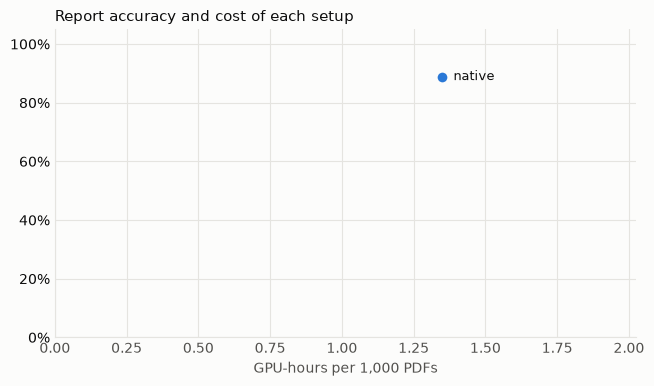

,gentrex transcribe (s),gentrex select (s),gentrex extract (s),gentrex normalize (s),Model loading (s),PDFs,Failed files,Reports without a record,Prompt tokens per PDF,Completion tokens per PDF,"Seconds per 1,000 PDFs","GPU-hours per 1,000 PDFs"
native,28.3,12.6,219.9,42.1,670.1,99.0,0.0,0.0,7197.0,476.0,3060.0,1.35


In [15]:
def time_numbers(run):
    commands = run["performance"]["commands"]
    loading = sum(c.get("server_start_seconds") or 0 for c in commands.values())
    files = run["performance"]["files"] or 1
    prompt = sum(c.get("prompt_tokens") or 0 for c in commands.values())
    completion = sum(c.get("completion_tokens") or 0 for c in commands.values())
    return {
        **{f"gentrex {name} (s)": c["seconds"] for name, c in commands.items()},
        "Model loading (s)": round(loading, 1),
        "PDFs": run["performance"]["files"],
        "Failed files": sum(c.get("failed_files") or 0 for c in commands.values()),
        "Reports without a record": run["without_record"],
        "Prompt tokens per PDF": round(prompt / files),
        "Completion tokens per PDF": round(completion / files),
        "Seconds per 1,000 PDFs": run["performance"]["seconds_per_1000_files"],
        "GPU-hours per 1,000 PDFs": run["performance"]["gpu_hours_per_1000_files"],
    }


times = pd.DataFrame({setup: time_numbers(run) for setup, run in chosen.items()}).T
bench.points(
    {
        setup: (
            run["performance"]["gpu_hours_per_1000_files"],
            run["main"]["report_accuracy"]["value"],
        )
        for setup, run in chosen.items()
        if run["performance"]["gpu_hours_per_1000_files"]
    },
    "Report accuracy and cost of each setup",
    "GPU-hours per 1,000 PDFs",
)
times

## One run

The rest is about one run, `RUN`. By default it is the newest run of the
native copy on `SPLIT`. For another run, put its folder name from the first
table in its place.

20261117-201846: 99 reports of the split dev, native; 0 reports have no record


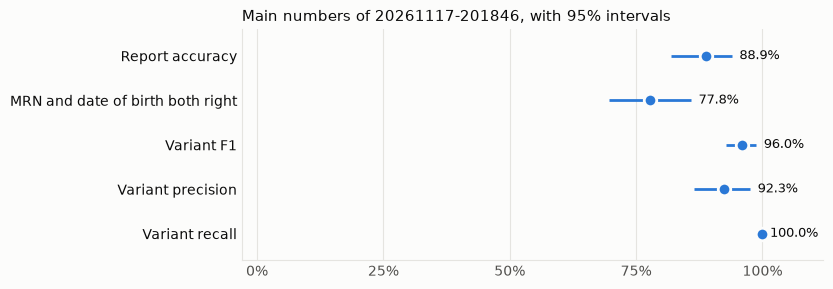

In [16]:
RUN = bench.newest(runs, SPLIT).get("native", list(runs)[-1])
scores = runs[RUN]
errors = bench.errors(RUN)
print(
    f"{RUN}: {scores['reports']} reports of the split {scores['split']},"
    f" {bench.setup_of(scores)}; {scores['without_record']} reports have no record"
)
bench.intervals(
    {label: scores["main"][name] for name, label in MAIN.items()},
    f"Main numbers of {RUN}, with 95% intervals",
)

### Errors per report

Report accuracy looks only at the clinical values. This counts every value
of a record, with the identifiers, dates and standard values.

6 of 99 reports have every value right (6.1%)


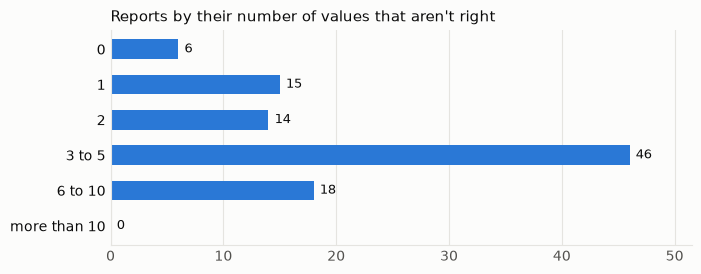

In [17]:
per_report = collections.Counter(errors["report"].tolist())
counts = [per_report[name] for name in scores["by_report"]]
print(
    f"{counts.count(0)} of {len(counts)} reports have every value right"
    f" ({bench.percent(counts.count(0) / len(counts))})"
)
BINS = {
    "0": (0, 0),
    "1": (1, 1),
    "2": (2, 2),
    "3 to 5": (3, 5),
    "6 to 10": (6, 10),
    "more than 10": (11, len(errors) + 11),
}
bench.bars(
    pd.Series(
        {
            label: sum(low <= count <= high for count in counts)
            for label, (low, high) in BINS.items()
        },
        dtype=float,
    ),
    "Reports by their number of values that aren't right",
    label=lambda number: f"{number:.0f}",
)

### Missed and extra variants

Variants and clinical features are matched one to one with the truth. A
missed one is in the report and not in the record. An extra one is in the
record and not true.

An extra one is a `distractor` if the report prints it for someone or
something else, as a variant from a cited study or a relative's feature. It
is a `hallucination` if the report doesn't print it that way. `Missed, by
command` names the command that lost each missed one.

The last row counts the clinical features by their HPO ID. `charged
earlier` marks a feature that was already extra before `gentrex normalize`
gave it an HPO term.

In [18]:
def causes(counts):
    return ", ".join(f"{count} {cause}" for cause, count in counts.items()) or "none"


pd.DataFrame(
    {
        name: {
            "Matched": entity["matched"],
            "Missed": entity["missed"],
            "Extra": entity["extra"],
            "Precision": bench.percent(entity["precision"]),
            "Recall": bench.percent(entity["recall"]),
            "F1": bench.percent(entity["f1"]),
            "Missed, by command": causes(entity["missed_by"]),
            "Extra, by cause": causes(entity["extra_by"]),
        }
        for name, entity in scores["entities"].items()
    }
).T

,Matched,Missed,Extra,Precision,Recall,F1,"Missed, by command","Extra, by cause"
variants,84,0,7,92.3%,100.0%,96.0%,none,"6 hallucination, 1 distractor"
patient_phenotypes,273,0,21,92.9%,100.0%,96.3%,none,"20 hallucination, 1 distractor"
normalized.patient_phenotypes,273,0,21,92.9%,100.0%,96.3%,none,"20 charged earlier, 1 normalize"


### Wrong reports

The clinical errors of the reports that don't count as correct.

In [19]:
wrong = [name for name, report in scores["by_report"].items() if not report["correct"]]
print(f"{len(wrong)} of {scores['reports']} reports count as wrong")
clinical = errors["report"].isin(wrong) & errors["field"].isin(sorted(bench.CLINICAL))
errors[clinical].drop(columns=["cause", "flagged"])

11 of 99 reports count as wrong


,report,field,result,truth,found,command
27,SYN-0008,variants,extra,NaN,trisomy 21,extract
33,SYN-0010,variants,extra,NaN,trisomy 21,extract
51,SYN-0015,variants,extra,NaN,FMR1 26 and 31 CGG repeats,extract
65,SYN-0017,variants.classification,extra,NaN,pathogenic,extract
72,SYN-0019,variants,extra,NaN,UBE3A loss of the expected biparental methylat...,extract
133,SYN-0037,variants.zygosity,extra,NaN,hemizygous,extract
166,SYN-0046,variants,extra,NaN,extra X chromosome,extract
242,SYN-0070,variants.classification,extra,NaN,pathogenic,extract
245,SYN-0071,variants,extra,NaN,UBE3A Only the paternal methylation pattern wa...,extract
255,SYN-0074,variants.classification,extra,NaN,other,extract


### Patient identification

A missed MRN or date of birth leaves the record without a patient, which a
person sees. A wrong or extra one files the record under another patient.

In [20]:
unmatched = sum(not report["patient_match"] for report in scores["by_report"].values())
print(
    f"{unmatched} of {scores['reports']} reports don't have both the MRN and the"
    " date of birth right"
)
pd.DataFrame(
    {
        name: {
            count: scores["fields"][name][count]
            for count in ("values", "correct", "missed", "wrong", "extra")
        }
        for name in ("mrn", "date_of_birth", "normalized.date_of_birth")
        if name in scores["fields"]
    }
).T

22 of 99 reports don't have both the MRN and the date of birth right


,values,correct,missed,wrong,extra
mrn,99,79,19,0,1
date_of_birth,99,97,1,1,0
normalized.date_of_birth,99,96,2,1,0


### Kinds of report

Report accuracy of each kind of report, with its 95% interval and the
number of reports. Groups with few reports have wide intervals. The plot
shows the challenge tags, weakest first.

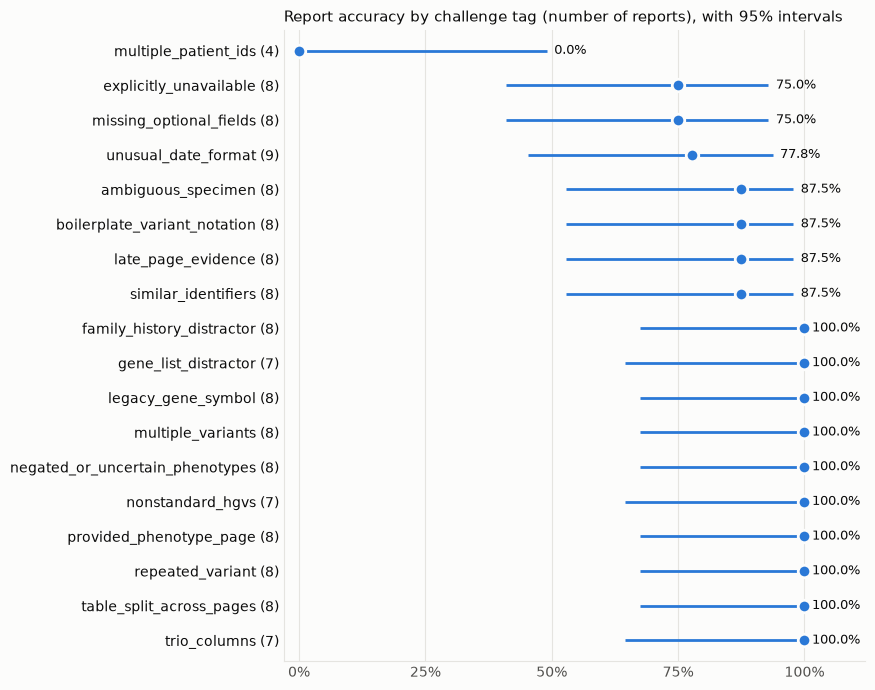

Report accuracy
Group                  Value                                              
Kind of test           array                100.0% (75.7% to 100.0%) of 12
                       carrier              100.0% (80.6% to 100.0%) of 16
                       exome                100.0% (80.6% to 100.0%) of 16
                       karyotype                20.0% (3.6% to 62.4%) of 5
                       methylation               0.0% (0.0% to 65.8%) of 2
                       mito                  100.0% (51.0% to 100.0%) of 4
                       panel                100.0% (83.9% to 100.0%) of 20
                       repeat                  60.0% (23.1% to 88.2%) of 5
                       single_gene           100.0% (70.1% to 100.0%) of 9
                       sma                       0.0% (0.0% to 56.2%) of 3
                       targeted              100.0% (64.6% to 100.0%) of 7
Result                 carrier                83.3% (55.2% to 95.3%) of 12
                       indeterminate         100.0% (34.2% to 100.0%) of 2
                       mixed                 100.0% (56.6% to 100.0%) of 5
                       negative               95.8% (79.8% to 99.3%) of 24
                       positive               80.5% (66.0% to 89.8%) of 41
                       secondary_finding     100.0% (34.2% to 100.0%) of 2
                       vus_only             100.0% (77.2% to 100.0%) of 13
Variants in the report 0                      76.7% (59.1% to 88.2%) of 30
                       1                      92.6% (82.4% to 97.1%) of 54
                       2 or more            100.0% (79.6% to 100.0%) of 15
Template               carrier-banner        100.0% (56.6% to 100.0%) of 5
                       chart                 100.0% (64.6% to 100.0%) of 7
                       dx-banner             100.0% (61.0% to 100.0%) of 6
                       enterprise                0.0% (0.0% to 43.4%) of 5
                       exome-box             100.0% (56.6% to 100.0%) of 5
                       exome-findings        100.0% (56.6% to 100.0%) of 5
                       findings-grid         100.0% (61.0% to 100.0%) of 6
                       graybar-panel         100.0% (61.0% to 100.0%) of 6
                       karyotype                20.0% (3.6% to 62.4%) of 5
                       microarray-printout   100.0% (61.0% to 100.0%) of 6
                       one-page              100.0% (56.6% to 100.0%) of 5
                       patient-page          100.0% (56.6% to 100.0%) of 5
                       results-statement     100.0% (61.0% to 100.0%) of 6
                       screen-badge          100.0% (56.6% to 100.0%) of 5
                       snp-array             100.0% (56.6% to 100.0%) of 5
                       summary-line            66.7% (30.0% to 90.3%) of 6
                       summary-sidebar       100.0% (61.0% to 100.0%) of 6
                       teal-banner           100.0% (56.6% to 100.0%) of 5
Templates              seen in dev            88.9% (81.2% to 93.7%) of 99

In [21]:
def group_numbers(group):
    labels = scores["groups"].get(group, {})
    found = {
        f"{label} ({numbers['reports']})": bench.wilson(
            round(numbers["report_accuracy"] * numbers["reports"]), numbers["reports"]
        )
        for label, numbers in labels.items()
    }
    return dict(sorted(found.items(), key=lambda item: item[1]["value"] or 0))


bench.intervals(
    group_numbers("tag"),
    "Report accuracy by challenge tag (number of reports), with 95% intervals",
)
pd.DataFrame(
    [
        {"Group": GROUPS[group], "Value": label, "Report accuracy": text}
        for group in ("kind", "scenario", "variants", "lab", "held_out")
        for label, text in group_table(scores, group).items()
    ]
).set_index(["Group", "Value"])

### Fields

Every field, weakest first, and a plot of the 15 weakest. The accuracy
accepts another spelling of the same value, as `c.5266dupC` for
`c.5266dup`, and `strict` counts the values that are the same character for
character. A missed value is in the report and not in the record. An extra
one is in the record and not in the report. A wrong one differs from the
report.

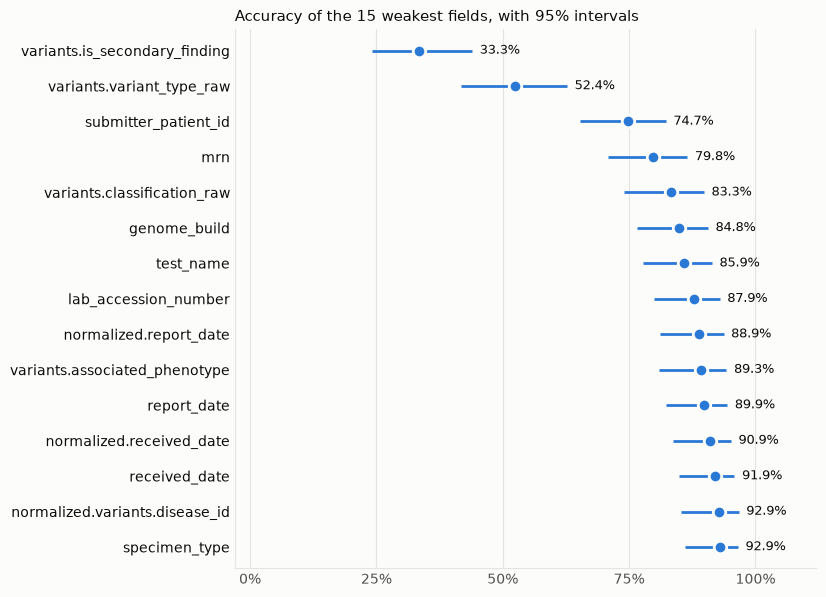

,accuracy (95% interval),values,correct,strict,missed,wrong,extra
variants.is_secondary_finding,33.3% (24.2% to 43.9%),84,28,28,0,0,56
variants.variant_type_raw,52.4% (41.8% to 62.7%),84,44,44,0,1,39
submitter_patient_id,74.7% (65.4% to 82.3%),99,74,74,1,4,20
mrn,79.8% (70.8% to 86.5%),99,79,79,19,0,1
variants.classification_raw,83.3% (73.9% to 89.8%),84,70,67,0,11,3
genome_build,84.8% (76.5% to 90.6%),99,84,84,15,0,0
test_name,85.9% (77.7% to 91.4%),99,85,85,0,14,0
lab_accession_number,87.9% (80.0% to 92.9%),99,87,87,5,7,0
normalized.report_date,88.9% (81.2% to 93.7%),99,88,88,3,8,0
variants.associated_phenotype,89.3% (80.9% to 94.3%),84,75,75,0,5,4


In [22]:
fields = dict(
    sorted(scores["fields"].items(), key=lambda item: item[1]["accuracy"] or 0)
)


def field_interval(numbers):
    return bench.wilson(numbers["correct"], numbers["values"])


bench.intervals(
    {name: field_interval(numbers) for name, numbers in list(fields.items())[:15]},
    "Accuracy of the 15 weakest fields, with 95% intervals",
)
COUNTS = ("values", "correct", "strict", "missed", "wrong", "extra")
pd.DataFrame(
    {
        name: {
            "accuracy (95% interval)": bench.with_interval(field_interval(numbers)),
            **{count: numbers[count] for count in COUNTS},
        }
        for name, numbers in fields.items()
    }
).T

### Standard values

A field that starts with `normalized.` is a standard value from
`gentrex normalize`, and it can only be right if its source was extracted
right. `End to end` is the share of all values that are right. `Given a
right source` leaves out the values whose source was already wrong, so it
measures `gentrex normalize` alone.

In [23]:
# An error of a standard value names no command if its source was wrong.
uncharged = errors.loc[errors["command"].isna(), "field"].tolist()


def normalize_numbers(name, numbers):
    source_wrong = uncharged.count(name)
    return {
        "Values": numbers["values"],
        "End to end": bench.with_interval(field_interval(numbers)),
        "Source already wrong": source_wrong,
        "Given a right source": bench.with_interval(
            bench.wilson(numbers["correct"], numbers["values"] - source_wrong)
        ),
    }


pd.DataFrame(
    {
        name: normalize_numbers(name, numbers)
        for name, numbers in sorted(fields.items())
        if name.startswith("normalized.")
    }
).T

,Values,End to end,Source already wrong,Given a right source
normalized.collection_date,99,99.0% (94.5% to 99.8%),0,99.0% (94.5% to 99.8%)
normalized.date_of_birth,99,97.0% (91.5% to 99.0%),2,99.0% (94.4% to 99.8%)
normalized.overall_result,99,100.0% (96.3% to 100.0%),0,100.0% (96.3% to 100.0%)
normalized.received_date,99,90.9% (83.6% to 95.1%),8,98.9% (94.0% to 99.8%)
normalized.report_date,99,88.9% (81.2% to 93.7%),10,98.9% (93.9% to 99.8%)
normalized.specimen_type,99,98.0% (92.9% to 99.4%),2,100.0% (96.2% to 100.0%)
normalized.test_started_date,99,98.0% (92.9% to 99.4%),2,100.0% (96.2% to 100.0%)
normalized.variants.clinvar_variation_id,64,98.4% (91.7% to 99.7%),0,98.4% (91.7% to 99.7%)
normalized.variants.disease_id,84,92.9% (85.3% to 96.7%),6,100.0% (95.3% to 100.0%)
normalized.variants.hgnc_id,84,98.8% (93.6% to 99.8%),0,98.8% (93.6% to 99.8%)


### The check of copied values

`gentrex extract` names the copied values that it can't find in the pages
(`not_in_pages`), for a person to check. `precision` is the share of the
named values that were wrong or extra. `recall` is the share of all wrong
or extra copied values that were named.

In [24]:
pd.Series(scores.get("not_in_pages") or {}, name=RUN, dtype=object).to_frame()

,20261117-201846
values,2082
flagged,56
not_right,173
flagged_and_not_right,5
precision,0.0893
recall,0.0289


### Pages

The pages that went to OCR, and the pages that `gentrex select` kept. The
counts need the run folders of the two commands on this machine.

In [25]:
all_pages = bench.records(scores, "transcribe", "pages.jsonl")
decisions = bench.records(scores, "select", "decisions.jsonl")
pd.Series(
    {
        "PDFs": len({page["file"] for page in all_pages}),
        "pages": len(all_pages),
        "pages sent to OCR": sum(page["source"] == "scanned" for page in all_pages),
        "pages without text after transcribe": sum(
            not page["text"] for page in all_pages
        ),
        "pages that gentrex select decided on": len(decisions),
        "pages kept": sum(decision["keep"] for decision in decisions),
    },
    name=RUN,
).to_frame()

,20261117-201846
PDFs,0
pages,0
pages sent to OCR,0
pages without text after transcribe,0
pages that gentrex select decided on,0
pages kept,0


### Every error

Every value of `RUN` that isn't right, counted by command and field, and
then the first 50. Filter `errors` to study one field or command, as in
`errors[errors["field"] == "mrn"]`.

In [26]:
errors.groupby(["command", "field"], dropna=False).size().to_frame("values")

values
command   field                                           
extract   clinical_indication                            2
          date_of_birth                                  2
          genome_build                                  15
          lab_accession_number                          12
          mrn                                           20
          patient_phenotypes                            21
          report_date                                    1
          specimen_type                                  7
          submitter_patient_id                          20
          test_name                                     14
          test_started_date                              1
          test_type                                      6
          variants                                       7
          variants.associated_phenotype                  9
          variants.chromosomal_position                  5
          variants.classification                        3
          variants.classification_raw                   14
          variants.dna_change_raw                        3
          variants.is_secondary_finding                 56
          variants.mode_of_inheritance_raw               3
          variants.parental_origin                       1
          variants.parental_origin_raw                   1
          variants.variant_type_raw                     40
          variants.zygosity                              2
          variants.zygosity_raw                          5
normalize normalized.collection_date                     1
          normalized.date_of_birth                       1
          normalized.patient_phenotypes                  1
          normalized.received_date                       1
          normalized.report_date                         1
          normalized.variants.clinvar_variation_id       1
          normalized.variants.hgnc_id                    1
select    received_date                                  8
          report_date                                    9
          submitter_patient_id                           5
          test_started_date                              1
          variants.mode_of_inheritance                   1
          variants.mode_of_inheritance_raw               1
          variants.transcript                            2
NaN       normalized.date_of_birth                       2
          normalized.patient_phenotypes                 20
          normalized.received_date                       8
          normalized.report_date                        10
          normalized.specimen_type                       2
          normalized.test_started_date                   2
          normalized.variants.disease_id                 6

In [27]:
errors.head(50)

,report,field,result,truth,found,command,cause,flagged
0,SYN-0001,date_of_birth,wrong,3 Apr 1986,4 Apr 1986,extract,NaN,True
1,SYN-0001,normalized.date_of_birth,wrong,1986-04-03,1986-04-04,NaN,NaN,None
2,SYN-0001,variants.is_secondary_finding,extra,NaN,False,extract,NaN,None
3,SYN-0002,patient_phenotypes,extra,NaN,Short stature,extract,hallucination,False
4,SYN-0002,patient_phenotypes,extra,NaN,congenital heart disease,extract,hallucination,False
5,SYN-0002,normalized.patient_phenotypes,extra,NaN,HP:0004322,NaN,NaN,None
6,SYN-0002,normalized.patient_phenotypes,extra,NaN,HP:0001627,NaN,NaN,None
7,SYN-0003,submitter_patient_id,extra,NaN,1500293345,extract,NaN,False
8,SYN-0003,received_date,missed,12/28/2023,None,select,NaN,None
9,SYN-0003,report_date,wrong,2/14/2024,2/15/2024,select,NaN,False
